In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

% matplotlib inline

In [2]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


In [12]:
file1 = 'images/Histology nuclei/TCGA-49-4488-01Z-00-DX1.tif'

img = cv.imread(file1)

# convert
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# split channels
b, g, r = cv.split(img)


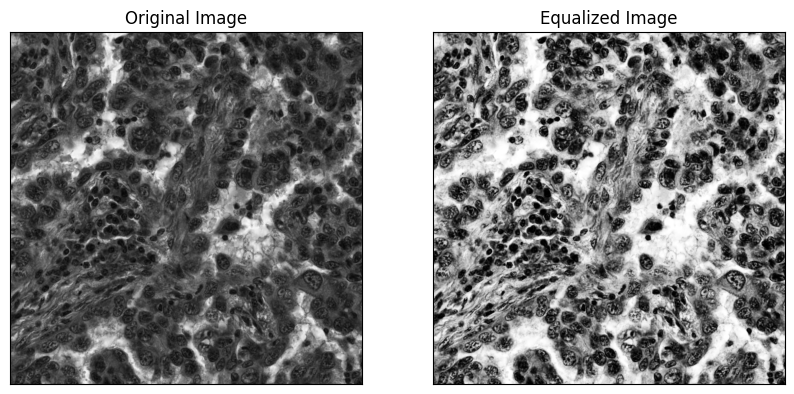

In [16]:
# Apply histogram equalization
equ = cv.equalizeHist(gray_img)

# plot images
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(gray_img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(equ, cmap='gray')
plt.title('Equalized Image'), plt.xticks([]), plt.yticks([])
plt.show()

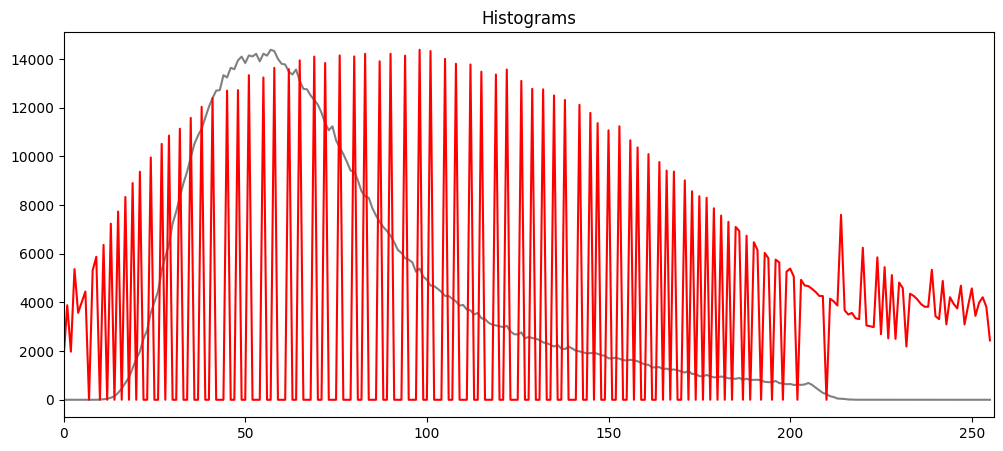

In [20]:
gray_hist = cv.calcHist([gray_img], [0], None, [256], [0, 256])
equ_hist = cv.calcHist([equ], [0], None, [256], [0, 256])

# plot histograms
plt.figure(figsize=(12, 5))
plt.title('Histograms')
plt.plot(gray_hist, color='gray')
plt.plot(equ_hist, color='red')
plt.xlim([0, 256])
plt.show()

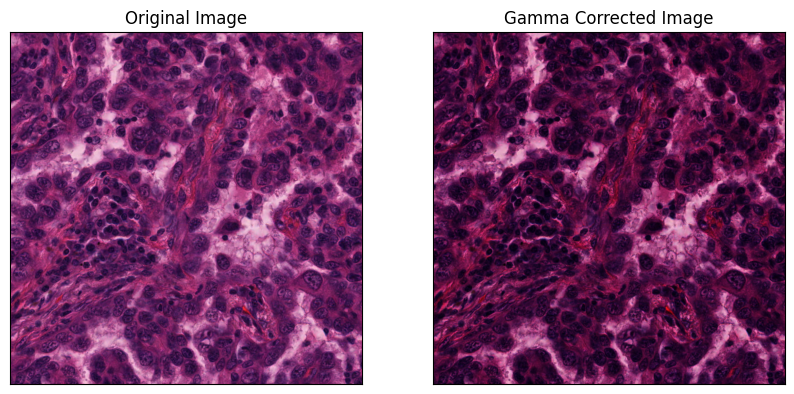

In [22]:
# Adjust the gamma value
gamma = 1.5
img_corrected = np.power(img / float(np.max(img)), gamma)
img_corrected = np.uint8(img_corrected * 255)

# Display the results
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv.cvtColor(img_corrected, cv.COLOR_BGR2RGB))
plt.title('Gamma Corrected Image'), plt.xticks([]), plt.yticks([])
plt.show()